In [ ]:
# La Palma Eruption 2021

In [1]:
#import
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#import sat catalogue
!pip install pystac-client
from pystac_client import Client

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25/25 [pystac-client]


In [3]:
# identifeid images and dates on copernicus browser (15-09-21 - 08-01-22)
catalog = Client.open("https://earth-search.aws.element84.com/v1")

In [4]:
results = catalog.search(
    collections=["sentinel-2-c1-l2a"],    # which satellite: Sentinel-2
    bbox=[-17.98, 28.58, -17.84, 28.66],  # where: a box around the volcano
    datetime="2021-11-10/2021-11-30",     # when: around your birthday
)

In [5]:
#creating a dataframe list of dates
la_palma = pd.DataFrame(results.item_collection_as_dict()["features"])
la_palma = pd.json_normalize(la_palma["properties"])
la_palma[["datetime", "eo:cloud_cover"]]

,datetime,eo:cloud_cover
0,2021-11-29T12:03:43.823000Z,20.986812
1,2021-11-29T12:03:40.391000Z,33.961239
2,2021-11-24T12:03:40.048000Z,99.920285
3,2021-11-24T12:03:36.621000Z,84.056485
4,2021-11-19T12:03:44.089000Z,1.269206
5,2021-11-19T12:03:40.655000Z,7.257718
6,2021-11-14T12:03:42.851000Z,10.288340
7,2021-11-14T12:03:39.421000Z,12.274097


In [6]:
#import for imahge pixels
!pip install odc-stac

import odc.stac
import numpy as np

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [odc-stac]


In [7]:
bbox = [-17.98, 28.58, -17.84, 28.66]

results = catalog.search(
    collections=["sentinel-2-c1-l2a"],
    bbox=bbox,
    datetime="2021-11-19",
)
items = results.item_collection()
len(items)

/usr/local/lib/python3.13/dist-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


2

In [8]:
data = odc.stac.load(
    items,
    bands=["swir22", "swir16", "nir08"],  # B12, B11, B8A
    bbox=bbox,
    crs="EPSG:32628",      # the map projection for this part of the world, in metres
    resolution=20,         # each pixel = 20 m
    groupby="solar_day",   # stitch the two tiles into one image
)
data

<xarray.Dataset> Size: 2MB
Dimensions:      (y: 461, x: 697, time: 1)
Coordinates:
  * y            (y) float64 4kB 3.174e+06 3.174e+06 ... 3.165e+06 3.165e+06
  * x            (x) float64 6kB 2.085e+05 2.085e+05 ... 2.224e+05 2.224e+05
  * time         (time) datetime64[ns] 8B 2021-11-19T12:03:40.655000
    spatial_ref  int32 4B 32628
Data variables:
    swir22       (time, y, x) uint16 643kB 1031 1031 1022 ... 4499 4682 4354
    swir16       (time, y, x) uint16 643kB 1019 1015 1012 ... 4979 5130 4914
    nir08        (time, y, x) uint16 643kB 987 994 1003 991 ... 5781 5949 5610

Variable name is data. we have x and y given in Meters (not lat/long) .spatial_ref: 32628 means: EPSG:32628, the UTM projection for this part of the world. So x ≈ 208,500 m east and y ≈ 3,174,000 m north of the equator.


The time is in datetime64[ns]. The date and time is 19th November 2021

The data variables are Shortwave Infrared (SWIR) and NIR.


*   SWIR22 is band 12
*   SWIR16 is band 11
*   NIR08 is band 8A


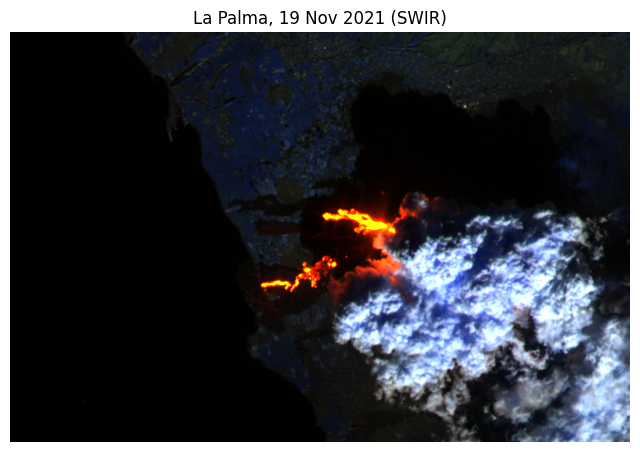

In [10]:
#creating the image using numpy
img = data.isel(time=0)   # take the first (only) date

rgb = np.dstack([img["swir22"], img["swir16"], img["nir08"]]).astype(float)

# stretch the brightness so it looks good (like adjusting contrast)
low, high = np.percentile(rgb, [2, 98])
rgb = np.clip((rgb - low) / (high - low), 0, 1)

plt.figure(figsize=(8, 8))
plt.imshow(rgb)
plt.title("La Palma, 19 Nov 2021 (SWIR)")
plt.axis("off")
plt.show()


In [18]:
#search for the full range of dates 15-09-2021 - 08-01-22
all_results = catalog.search(
    collections=["sentinel-2-c1-l2a"],    # which satellite: Sentinel-2; same
    bbox=[-17.98, 28.58, -17.84, 28.66],  # where: a box around the volcano; same
    datetime="2021-09-15/2022-01-08",     # when: changed to full range
)


In [20]:
#we have searched. now we want to label our cards
cards = all_results.item_collection()     # the cards
print(len(cards), "cards")

44 cards


/usr/local/lib/python3.13/dist-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


In [19]:
#create database of all passes
all_images = pd.DataFrame(all_results.item_collection_as_dict()["features"])
all_images = pd.json_normalize(all_images["properties"])
all_images[["datetime", "eo:cloud_cover"]]
#note to self, each day has two passes

,datetime,eo:cloud_cover
0,2021-12-29T12:03:45.672000Z,53.071278
1,2021-12-29T12:03:42.239000Z,44.440812
2,2021-12-24T12:03:39.199000Z,66.637820
3,2021-12-24T12:03:35.768000Z,48.812944
4,2021-12-19T12:03:44.727000Z,8.418004
5,2021-12-19T12:03:41.293000Z,4.803076
6,2021-12-14T12:03:37.995000Z,6.226764
7,2021-12-14T12:03:34.565000Z,2.131023
8,2021-12-09T12:03:42.609000Z,27.663881
9,2021-12-09T12:03:39.177000Z,47.346738


In [21]:
# download pixels and bands
all_data = odc.stac.load(
    cards,
    bands=["swir22", "swir16", "nir08"],
    bbox=bbox,
    crs="EPSG:32628",
    resolution=20,
    groupby="solar_day",
)
print(len(all_data.time), "days")

22 days


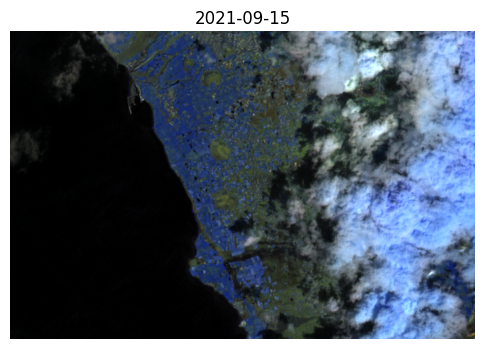

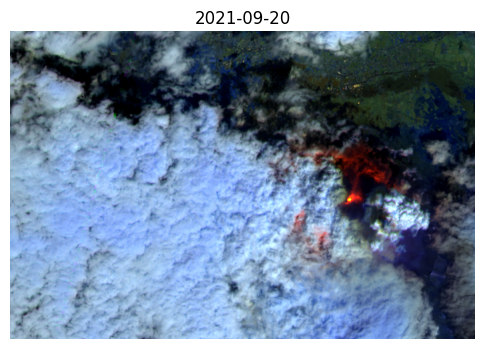

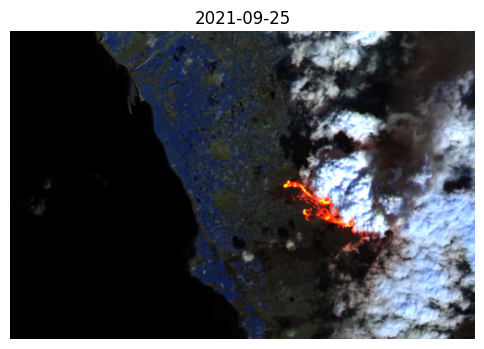

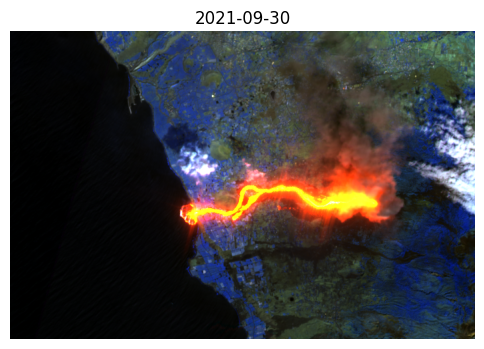

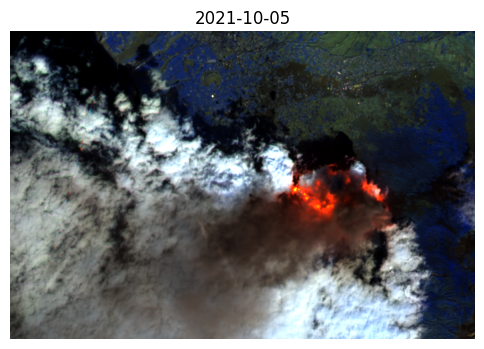

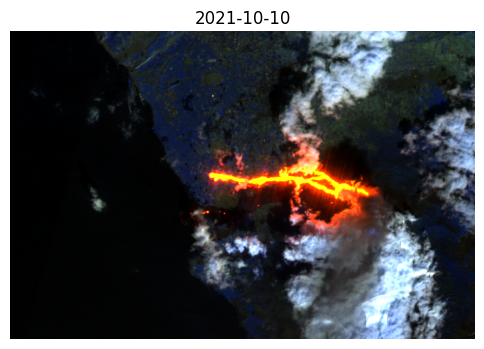

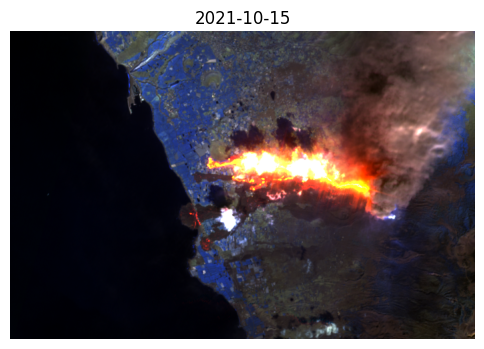

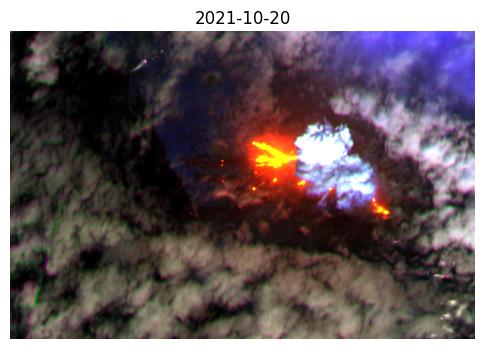

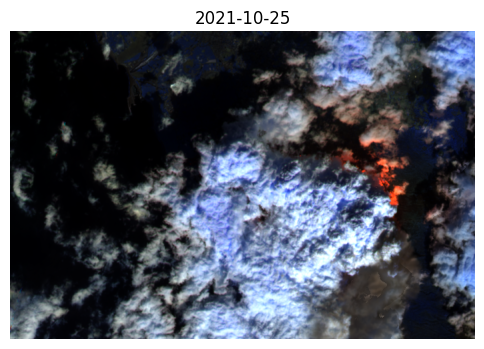

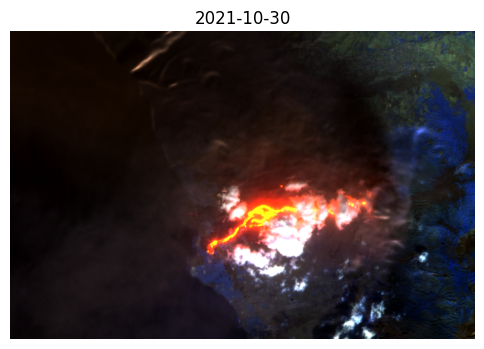

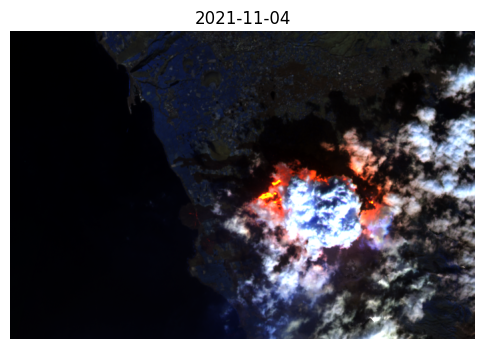

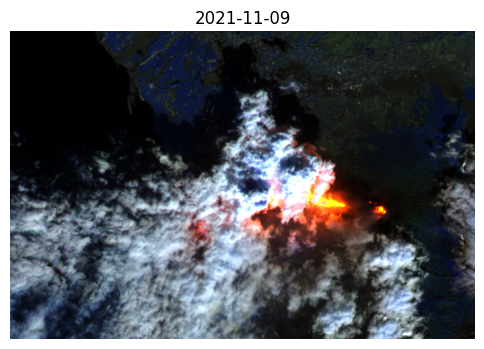

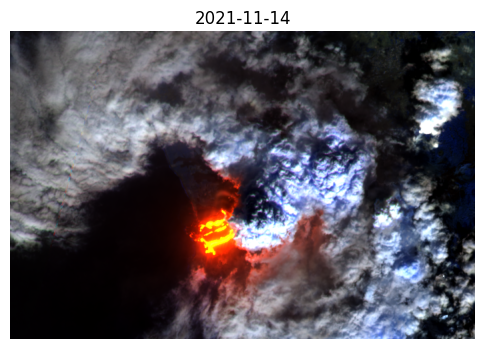

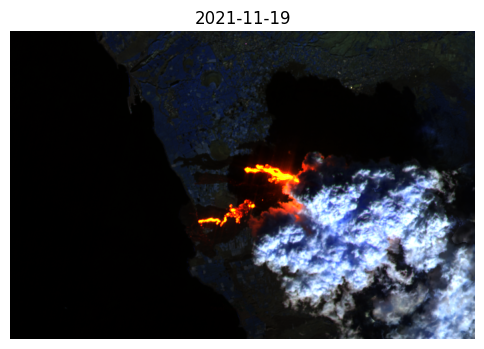

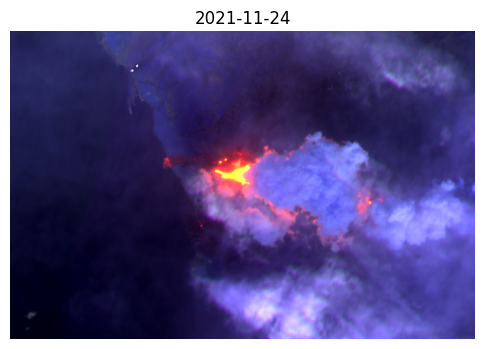

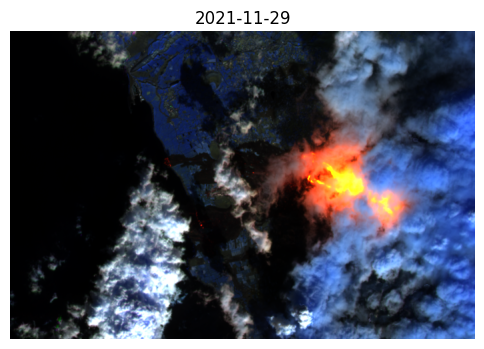

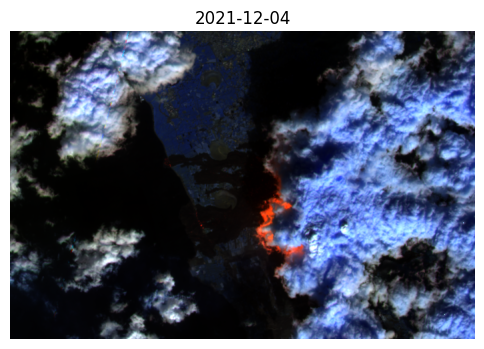

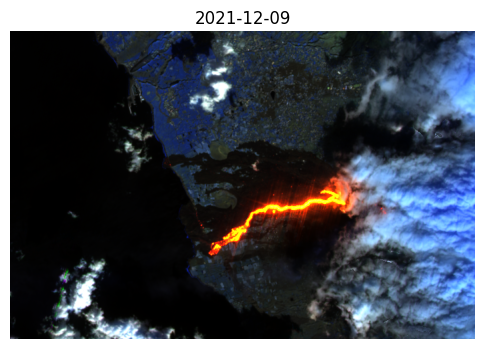

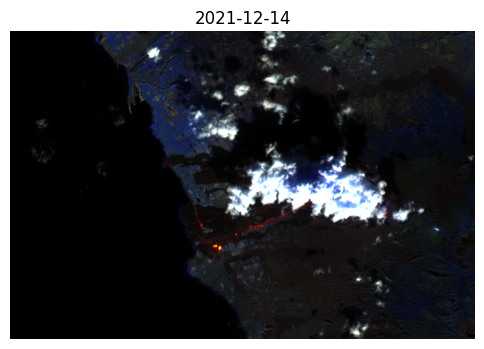

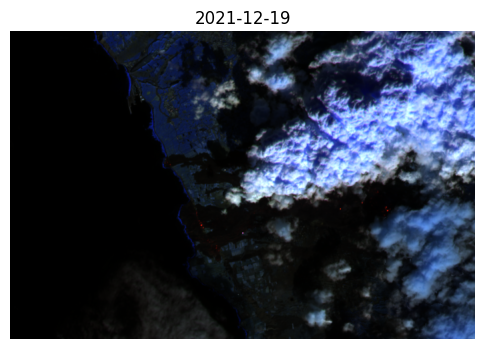

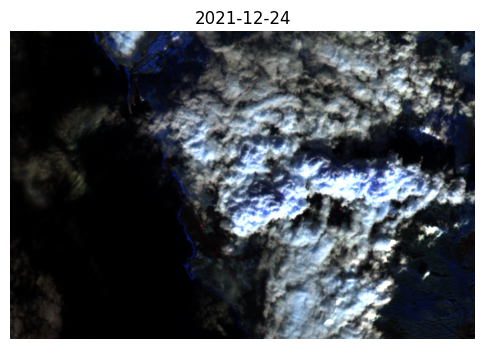

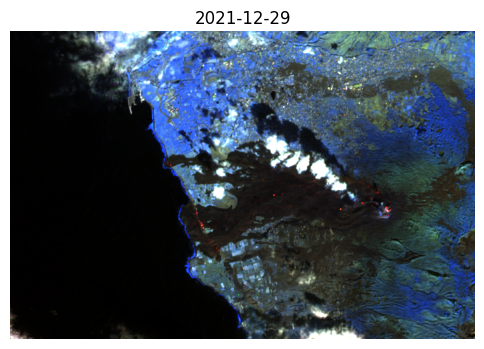

In [22]:
#To create a loop for all 22 days and images to generate
for i in range(22):
    img = all_data.isel(time=i)      # pick day number i

    rgb = np.dstack([img["swir22"], img["swir16"], img["nir08"]]).astype(float)
    low, high = np.percentile(rgb, [2, 98])
    rgb = np.clip((rgb - low) / (high - low), 0, 1)

    plt.figure(figsize=(6, 6))
    plt.imshow(rgb)
    plt.title(str(img.time.values)[:10])   # the date as the title
    plt.axis("off")
    plt.show()